# MFE-FCGAT, Case A: window-level evaluation (the paper's protocol)

The model, the data and the training code are copied unchanged from
`GAT_ds004504.ipynb`. **The train/test split changes**, and one
hyperparameter: the MLP dropout is (0.5, 0.2) instead of the paper's (0.8, 0.5),
chosen on validation windows (Cell 2). This is the
protocol behind the base paper's headline numbers (Liu et al. 2025, Table 3:
accuracy 95.09 %, AUC 98.36 %), so this notebook is the like-for-like
comparison with that table.

| | **Case A** (this notebook) | **Case B** (`GAT_ds004504.ipynb`) |
|---|---|---|
| what is split into train / test | 20 s **windows**, shuffled | **subjects** |
| same person in train and test? | yes, different windows of them | never |
| question it answers | does the model recognise AD in further recordings of people it was trained on? | can it diagnose a person it has never seen? |
| comparable to | Liu et al. 2025 Table 3 and other window/epoch-split studies | subject-independent studies |
| headline unit | window | subject |

**Why Case A scores higher.** Windows overlap by 75 %, so most test windows
share 15 of their 20 seconds with a training window of the same person, and
the model can partly recognise the person rather than the disease. The
band-power logistic regression in Cell 5 shows the size of that effect: it
uses no graph at all and still scores about 0.92 under this split. Always
present Case A with its label, next to Case B.

**Protocol.** Stratified 5-fold CV over windows (each fold is an 80 / 20
train / test split, like the paper's 8 : 2). A random fifth of the training
windows is the validation set that picks the epoch, as in the paper. Metrics
are the paper's five, computed per window: accuracy, recall, precision, F1 and
AUC. They are reported pooled over all 5,758 windows and as mean ± SD over the
folds, which is the paper's format (they averaged 20 runs).

In [1]:
# ===========================================================================
# CELL 1 — IMPORTS, PATHS, DEVICE
# ===========================================================================
import copy, json, math, random, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

WORK_DIR   = Path.cwd()
CACHE_DIR  = WORK_DIR / "subject_cache"      # point elsewhere if the cache lives elsewhere
RESULT_DIR = WORK_DIR / "results_gat_window"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


print(f"torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"cache   : {CACHE_DIR}  ({len(list(CACHE_DIR.glob('sub-*.npz')))} files)")
print(f"results : {RESULT_DIR}")

torch 2.14.0+cpu | device cpu
cache   : c:\Projects\Major Project\subject_cache  (88 files)
results : c:\Projects\Major Project\results_gat_window


In [2]:
# ===========================================================================
# CELL 2 — CONFIGURATION  (the only cell you normally edit)
# ===========================================================================
SEED = 42

# --- data: fixed by the cache ----------------------------------------------
BAND_NAMES = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]
BAND_DIMS  = {"Delta": 18, "Theta": 21, "Alpha": 26, "Beta": 86, "Gamma": 76}  # PSD bins @ 0.2 Hz
N_NODES    = 19            # electrodes
N_SUBJECTS = 65            # sub-001..036 AD (label 1), sub-037..065 HC (label 0)
N_AD       = 36

# --- model -------------------------------------------------------------------
CNN_OUT_DIM  = 16          # paper D_out = 16  ->  kernels 3, 6, 11, 71, 61
GAT_HIDDEN   = 16          # layer 1 width (paper's first graph layer)
GAT_OUT      = 5           # layer 2 width (paper's second graph layer)
HEADS        = 4           # attention heads per layer, averaged
ATTN_DROPOUT = 0.1         # dropout on the attention coefficients
MLP_HIDDEN   = (30, 14)    # paper
MLP_DROPOUT  = (0.5, 0.2)  # paper: (0.8, 0.5). Lighter here: chosen on fold-1 VALIDATION windows
                           # (val AUC 0.989 vs 0.982 with the paper's dropout); the heavy dropout
                           # caps how much the head can learn under the window split

# --- training (identical to GCN_ds004504.ipynb except LR) --------------------
# Not tuned yet for this model: check 1.2e-4, 1e-3 and 3e-3.
LR           = 3e-3
WEIGHT_DECAY = 1e-4        # from the released code; the paper does not state one
BATCH_SIZE   = 64          # paper
MAX_EPOCHS   = 120         # also the cosine horizon. The window split needs far more epochs than
                           # the subject split (validation keeps improving); sized by a one-fold probe
MIN_EPOCHS   = 15          # no checkpoint before this; the earliest epochs are noise
PATIENCE     = 20          # stop after this many epochs without improvement (paper: 20)
GRAD_CLIP    = 5.0

# --- protocol ---------------------------------------------------------------
# Case A: windows are split, so the same person appears in train and test.
# Case B (subjects split) is GAT_ds004504.ipynb.
SPLIT_LEVEL = "window"
N_FOLDS     = 5
N_REPEATS   = 1            # use 3+ before any number goes into a write-up

assert SPLIT_LEVEL == "window", "Case B lives in GAT_ds004504.ipynb"
assert [BAND_DIMS[b] - CNN_OUT_DIM + 1 for b in BAND_NAMES] == [3, 6, 11, 71, 61]
seed_all(SEED)
print(f"MFE-FCGAT, Case A | lr {LR} | {N_REPEATS} x {N_FOLDS}-fold, {SPLIT_LEVEL}-level | "
      f"max {MAX_EPOCHS} epochs, warm-up {MIN_EPOCHS}, patience {PATIENCE}")

MFE-FCGAT, Case A | lr 0.003 | 1 x 5-fold, window-level | max 120 epochs, warm-up 15, patience 20


In [3]:
# ===========================================================================
# CELL 3 — LOAD THE FEATURE CACHE
# ===========================================================================
# One .npz per subject; one row per 20 s window (75 % overlap):
#   x_<Band>  (n, 19, F_f)       log PSD, normalised per window     paper Eq. 1
#   e1        (n, 5, 19, 19)     |Pearson| graph, row-normalised    Eqs. 2-3
#   e2        (n, 5, 19, 19)     mutual-information graph           Eqs. 4-5
#   bp        (n, 5, 19)         mean log band power (Cell 4 only)
x_parts = {b: [] for b in BAND_NAMES}
e1_parts, e2_parts, bp_parts, y_parts, sid_parts = [], [], [], [], []

for i in range(1, N_SUBJECTS + 1):
    sid = f"sub-{i:03d}"
    with np.load(CACHE_DIR / f"{sid}.npz") as z:
        for b in BAND_NAMES:
            assert z[f"x_{b}"].shape[1:] == (N_NODES, BAND_DIMS[b]), (sid, b)
            x_parts[b].append(z[f"x_{b}"])
        e1_parts.append(z["e1"]); e2_parts.append(z["e2"])
        bp_parts.append(z["bp"]); y_parts.append(z["y"])
        sid_parts.append(np.full(len(z["y"]), sid))
    # a re-cached subject must never silently flip class
    assert int(y_parts[-1][0]) == (1 if i <= N_AD else 0), f"{sid}: wrong label"

X   = [np.concatenate(x_parts[b]).astype(np.float32) for b in BAND_NAMES]
E1  = np.concatenate(e1_parts).astype(np.float32)
E2  = np.concatenate(e2_parts).astype(np.float32)
BP  = np.concatenate(bp_parts).astype(np.float32)
Y   = np.concatenate(y_parts).astype(np.int64)
SID = np.concatenate(sid_parts)
del x_parts, e1_parts, e2_parts, bp_parts, y_parts, sid_parts

# The whole dataset (~180 MB) lives on the device; batches are index slices.
Xt  = [torch.from_numpy(a).to(DEVICE) for a in X]
E1t = torch.from_numpy(E1).to(DEVICE)
E2t = torch.from_numpy(E2).to(DEVICE)
Yt  = torch.from_numpy(Y).to(DEVICE)

print(f"windows  : {len(Y):,}  (AD {int((Y == 1).sum()):,} / HC {int((Y == 0).sum()):,})")
print(f"subjects : {len(np.unique(SID))}  (AD {N_AD} / HC {N_SUBJECTS - N_AD})")
for b, a in zip(BAND_NAMES, X):
    print(f"  x_{b:<6s} {a.shape}")
print(f"  e1       {E1.shape}\n  e2       {E2.shape}")

windows  : 5,758  (AD 2,858 / HC 2,900)
subjects : 65  (AD 36 / HC 29)
  x_Delta  (5758, 19, 18)
  x_Theta  (5758, 19, 21)
  x_Alpha  (5758, 19, 26)
  x_Beta   (5758, 19, 86)
  x_Gamma  (5758, 19, 76)
  e1       (5758, 5, 19, 19)
  e2       (5758, 5, 19, 19)


In [4]:
# ===========================================================================
# CELL 4 — SPLITS AND METRICS
# ===========================================================================
def make_splits(level=SPLIT_LEVEL, n_folds=N_FOLDS, n_repeats=N_REPEATS, seed=SEED):
    """The outer K-fold picks the test set; 1/5 of the remainder becomes validation.

    Within each repeat, every window (and so every subject) is tested exactly once.
    """
    splits, idx = [], np.arange(len(Y))
    for r in range(1, n_repeats + 1):
        rs = seed + 1000 * r
        outer = (StratifiedGroupKFold(n_folds, shuffle=True, random_state=rs).split(idx, Y, groups=SID)
                 if level == "subject" else
                 StratifiedKFold(n_folds, shuffle=True, random_state=rs).split(idx, Y))
        for f, (trainval, test) in enumerate(outer, start=1):
            inner = StratifiedKFold(5, shuffle=True, random_state=rs + f)
            if level == "subject":
                # Hold out validation SUBJECTS, so early stopping is never
                # judged on people the model is training on.
                subs = np.unique(SID[trainval])
                labs = np.array([Y[SID == s][0] for s in subs])
                _, va = next(inner.split(subs, labs))
                is_val = np.isin(SID[trainval], subs[va])
                train, val = trainval[~is_val], trainval[is_val]
                tr_s, va_s, te_s = set(SID[train]), set(SID[val]), set(SID[test])
                assert not (tr_s & te_s or va_s & te_s or tr_s & va_s), "SUBJECT LEAKAGE"
            else:
                tr, va = next(inner.split(trainval, Y[trainval]))
                train, val = trainval[tr], trainval[va]
            splits.append(dict(repeat=r, fold=f, train=train, val=val, test=test))
    return splits


def _metrics(y, p):
    pred = (p >= 0.5).astype(int)
    return dict(acc=accuracy_score(y, pred),
                sens=recall_score(y, pred, zero_division=0),
                prec=precision_score(y, pred, zero_division=0),
                spec=recall_score(1 - y, 1 - pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0),
                auc=roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan)


def score(idx, prob):
    """Window-level (w_*) and subject-level (s_*) metrics.
    A subject's probability is the mean over its windows."""
    sid, y = SID[idx], Y[idx]
    subs = np.unique(sid)
    s_p = np.array([prob[sid == s].mean() for s in subs])
    s_y = np.array([y[sid == s][0] for s in subs])
    return {**{f"w_{k}": v for k, v in _metrics(y, prob).items()},
            **{f"s_{k}": v for k, v in _metrics(s_y, s_p).items()}}


SPLITS = make_splits()
_ns = lambda i: len(np.unique(SID[i]))
for s in SPLITS:
    print(f"r{s['repeat']} f{s['fold']}: train {len(s['train']):5d}w/{_ns(s['train']):2d}s | "
          f"val {len(s['val']):4d}w/{_ns(s['val']):2d}s | test {len(s['test']):4d}w/{_ns(s['test']):2d}s")
_tested = np.concatenate([s["test"] for s in SPLITS if s["repeat"] == 1])
assert len(_tested) == len(np.unique(_tested)) == len(Y)
print(f"each repeat tests all {len(Y):,} windows / {_ns(_tested)} subjects exactly once")

r1 f1: train  3684w/65s | val  922w/65s | test 1152w/65s
r1 f2: train  3684w/65s | val  922w/65s | test 1152w/65s
r1 f3: train  3684w/65s | val  922w/65s | test 1152w/65s
r1 f4: train  3685w/65s | val  922w/65s | test 1151w/65s
r1 f5: train  3685w/65s | val  922w/65s | test 1151w/65s
each repeat tests all 5,758 windows / 65 subjects exactly once


In [5]:
# ===========================================================================
# CELL 5 — THE BAR: band power -> logistic regression, same window folds
# ===========================================================================
# 95 numbers per window (5 bands x 19 electrodes of mean log power), no graph.
# Fitted on the same train + validation windows the network sees, tested on the
# same test windows. Under a window split this simple model already scores
# about 0.92: that is the part of Case A that comes from recognising people.
feat = BP.reshape(len(BP), -1)
FLOOR_OOF = np.full((N_REPEATS, len(Y)), np.nan)
for sp in SPLITS:
    fit = np.concatenate([sp["train"], sp["val"]])
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))
    FLOOR_OOF[sp["repeat"] - 1, sp["test"]] = clf.fit(feat[fit], Y[fit]).predict_proba(feat[sp["test"]])[:, 1]

FLOOR = pd.DataFrame([score(np.arange(len(Y)), FLOOR_OOF[r]) for r in range(N_REPEATS)]).mean()
print(f"linear floor, window level : acc {FLOOR['w_acc']:.4f}  recall {FLOOR['w_sens']:.4f}  "
      f"precision {FLOOR['w_prec']:.4f}  F1 {FLOOR['w_f1']:.4f}  AUC {FLOOR['w_auc']:.4f}")

linear floor, window level : acc 0.9220  recall 0.9237  precision 0.9195  F1 0.9216  AUC 0.9771


---
## Model

Three things to know before reading the code:

- **Why `+ log E`.** Every graph links all 19 electrodes to each other. A plain
  GAT would have no structure to work from, so the Pearson and MI graphs would
  be ignored. Adding `log E` inside the softmax is the same as multiplying the
  attention by `E` and renormalising. At the start of training the layer is a
  connectivity-weighted average, close to the GCN. Training then reshapes the
  weights.
- **Why classic GAT is enough.** In classic GAT the learned score
  `a·Wx_i + a·Wx_j` ranks neighbours the same way for every electrode. This is
  the weakness GATv2 was designed to fix. The `log E` term is different for
  each pair and each window, so the final attention still varies by electrode.
  In earlier runs in this project (`results_mfagat/C_attn_v1`), the classic
  layer was also the faster and higher-scoring GAT variant.
- **Pearson first, MI second**, as in paper Eq. 8, with separate weights for
  each band. The only difference from `GCN_ds004504.ipynb` is `BandGAT` here
  versus `BandGCN` there.

In [6]:
# ===========================================================================
# CELL 6 — MODEL
# ===========================================================================
class BandCNN(nn.Module):
    """Paper Eq. 6: one Conv1d(1, 1, D_f) per band, shared across the 19 electrodes.

    D_f = F_f - 16 + 1, so every band comes out 16 wide and keeps its frequency order.
    """
    def __init__(self):
        super().__init__()
        self.convs = nn.ModuleList([nn.Conv1d(1, 1, BAND_DIMS[b] - CNN_OUT_DIM + 1)
                                    for b in BAND_NAMES])

    def forward(self, x, band):                    # (B, 19, F_f) -> (B, 19, 16)
        b, n, f = x.shape
        return self.convs[band](x.reshape(b * n, 1, f)).reshape(b, n, CNN_OUT_DIM)


class GATLayer(nn.Module):
    """Classic multi-head GAT (Velickovic et al. 2018), dense over 19 electrodes.

        h_i   = W x_i                                    (per head)
        e_ij  = LeakyReLU(a_src . h_i + a_dst . h_j) + log E_ij
        alpha = softmax_j(e_ij)
        out_i = mean over heads of  sum_j alpha_ij h_j
    """
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.heads, self.out_dim = HEADS, out_dim
        self.W     = nn.Linear(in_dim, HEADS * out_dim, bias=False)
        self.a_src = nn.Parameter(torch.empty(HEADS, 1, out_dim))
        self.a_dst = nn.Parameter(torch.empty(HEADS, 1, out_dim))
        self.bias  = nn.Parameter(torch.zeros(out_dim))
        self.drop  = nn.Dropout(ATTN_DROPOUT)
        for w in (self.W.weight, self.a_src, self.a_dst):
            nn.init.xavier_uniform_(w, gain=math.sqrt(2.0))

    def forward(self, x, adj):                     # x (B, 19, in), adj (B, 19, 19)
        b, n, _ = x.shape
        h   = self.W(x).view(b, n, self.heads, self.out_dim).transpose(1, 2)  # (B, H, 19, d)
        src = (h * self.a_src).sum(-1)                                        # (B, H, 19)
        dst = (h * self.a_dst).sum(-1)
        e   = F.leaky_relu(src.unsqueeze(-1) + dst.unsqueeze(-2), 0.2)        # (B, H, 19, 19)
        e   = e + torch.log(adj.clamp(min=1e-8)).unsqueeze(1)   # clamp: log(0) = -inf breaks softmax
        alpha = self.drop(torch.softmax(e, dim=-1))
        return (alpha @ h).mean(1) + self.bias                                # (B, 19, d)


class BandGAT(nn.Module):
    """Eq. 8 with attention in place of convolution: Pearson graph, then MI graph."""
    def __init__(self):
        super().__init__()
        self.g1 = GATLayer(CNN_OUT_DIM, GAT_HIDDEN)
        self.g2 = GATLayer(GAT_HIDDEN, GAT_OUT)

    def forward(self, x, e1, e2):                  # (B, 19, 16) -> (B, 19, 5)
        return F.elu(self.g2(F.elu(self.g1(x, e1)), e2))


class MFEFCGAT(nn.Module):
    """BandCNN -> per-band BandGAT -> concat 5 x 19 x 5 = 475 (Eq. 9) -> MLP."""
    def __init__(self):
        super().__init__()
        self.cnn  = BandCNN()
        self.gats = nn.ModuleList([BandGAT() for _ in BAND_NAMES])
        self.head = nn.Sequential(
            nn.Linear(len(BAND_NAMES) * N_NODES * GAT_OUT, MLP_HIDDEN[0]), nn.ReLU(),
            nn.Dropout(MLP_DROPOUT[0]),
            nn.Linear(MLP_HIDDEN[0], MLP_HIDDEN[1]), nn.ReLU(),
            nn.Dropout(MLP_DROPOUT[1]),
            nn.Linear(MLP_HIDDEN[1], 2))

    def forward(self, xs, e1, e2):                 # xs: 5 x (B, 19, F_f); e1, e2: (B, 5, 19, 19)
        z = [self.gats[i](self.cnn(xs[i], i), e1[:, i], e2[:, i]).flatten(1)
             for i in range(len(BAND_NAMES))]
        return self.head(torch.cat(z, dim=1))      # logits (B, 2)


_m  = MFEFCGAT()
_xs = [torch.randn(8, N_NODES, BAND_DIMS[b]) for b in BAND_NAMES]
_e  = torch.rand(8, len(BAND_NAMES), N_NODES, N_NODES)
print(f"parameters : {sum(p.numel() for p in _m.parameters()):,}   (GCN version: 16,686)")
print(f"smoke test : logits {tuple(_m(_xs, _e, _e).shape)}")
del _m, _xs, _e

parameters : 22,566   (GCN version: 16,686)
smoke test : logits (8, 2)


In [7]:
# ===========================================================================
# CELL 7 — TRAINING
# ===========================================================================
def batches(idx, size=BATCH_SIZE, shuffle=False, rng=None):
    order = rng.permutation(len(idx)) if shuffle else np.arange(len(idx))
    for s in range(0, len(idx), size):
        sel = torch.as_tensor(idx[order[s:s + size]], device=DEVICE)
        yield [x[sel] for x in Xt], E1t[sel], E2t[sel], Yt[sel]


@torch.no_grad()
def predict(model, idx):
    """P(AD) for each window, in the order of idx."""
    model.eval()
    return torch.cat([torch.softmax(model(xs, e1, e2), 1)[:, 1]
                      for xs, e1, e2, _ in batches(idx, size=512)]).cpu().numpy()


def train_fold(split):
    """Train on split['train'], keep the epoch with the best validation AUC, predict test."""
    seed = SEED + 1000 * split["repeat"] + split["fold"]
    seed_all(seed)
    rng = np.random.default_rng(seed)

    model = MFEFCGAT().to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS, eta_min=LR * 0.01)
    key   = "s_auc" if SPLIT_LEVEL == "subject" else "w_auc"   # select on what gets reported

    best, best_epoch, best_state, stale, history = -np.inf, 0, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        lr, total = opt.param_groups[0]["lr"], 0.0
        for xs, e1, e2, y in batches(split["train"], shuffle=True, rng=rng):
            loss = F.cross_entropy(model(xs, e1, e2), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            total += loss.item() * len(y)
        sched.step()

        val = score(split["val"], predict(model, split["val"]))
        history.append(dict(epoch=epoch, lr=lr, train_loss=total / len(split["train"]),
                            val_w_auc=val["w_auc"], val_s_acc=val["s_acc"], val_s_auc=val["s_auc"]))

        if epoch < MIN_EPOCHS:
            continue
        if val[key] > best:
            best, best_epoch, stale = val[key], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
            if stale >= PATIENCE:
                break

    model.load_state_dict(best_state)
    return dict(best_epoch=best_epoch, epochs_run=epoch,
                test_prob=predict(model, split["test"]), history=pd.DataFrame(history))


print("training functions ready")

training functions ready


In [8]:
# ===========================================================================
# CELL 8 — CROSS-VALIDATION
# ===========================================================================
rows, HISTORY = [], {}
OOF = np.full((N_REPEATS, len(Y)), np.nan)        # out-of-fold P(AD), one row per repeat
t0 = time.time()

for sp in SPLITS:
    ts = time.time()
    r = train_fold(sp)
    OOF[sp["repeat"] - 1, sp["test"]] = r["test_prob"]
    m = score(sp["test"], r["test_prob"])
    rows.append(dict(repeat=sp["repeat"], fold=sp["fold"], best_epoch=r["best_epoch"],
                     epochs_run=r["epochs_run"], seconds=round(time.time() - ts), **m))
    HISTORY[(sp["repeat"], sp["fold"])] = r["history"]
    r["history"].to_csv(RESULT_DIR / f"history_r{sp['repeat']}_f{sp['fold']}.csv", index=False)
    print(f"r{sp['repeat']} f{sp['fold']}  best epoch {r['best_epoch']:3d}/{r['epochs_run']:3d}  "
          f"window acc {m['w_acc']:.4f}  recall {m['w_sens']:.4f}  precision {m['w_prec']:.4f}  "
          f"F1 {m['w_f1']:.4f}  AUC {m['w_auc']:.4f}  [{rows[-1]['seconds']}s]", flush=True)

FOLDS = pd.DataFrame(rows)
FOLDS.to_csv(RESULT_DIR / "fold_results.csv", index=False)
np.save(RESULT_DIR / "oof_prob.npy", OOF)

# Pooled: every repeat scores all 5,758 windows once. Fold mean +- SD: the paper's format.
POOLED = pd.DataFrame([score(np.arange(len(Y)), OOF[r]) for r in range(N_REPEATS)])
P = POOLED.mean()
F_MEAN, F_SD = FOLDS.mean(numeric_only=True), FOLDS.std(numeric_only=True, ddof=1)
print(f"\nPOOLED  window  acc {P['w_acc']:.4f}  recall {P['w_sens']:.4f}  precision {P['w_prec']:.4f}  "
      f"F1 {P['w_f1']:.4f}  AUC {P['w_auc']:.4f}   [{(time.time() - t0) / 60:.1f} min]")
print("FOLDS   window  " + "  ".join(f"{n} {F_MEAN[k]:.4f} +- {F_SD[k]:.4f}" for n, k in
      [("acc", "w_acc"), ("recall", "w_sens"), ("precision", "w_prec"), ("F1", "w_f1"), ("AUC", "w_auc")]))

_ = (RESULT_DIR / "summary.json").write_text(json.dumps(dict(
    model="MFE-FCGAT", case="A: window-level split (paper protocol)",
    pooled=P.to_dict(), fold_mean=F_MEAN.to_dict(), fold_sd=F_SD.to_dict(), floor=FLOOR.to_dict(),
    config=dict(LR=LR, WEIGHT_DECAY=WEIGHT_DECAY, BATCH_SIZE=BATCH_SIZE, MAX_EPOCHS=MAX_EPOCHS,
                MIN_EPOCHS=MIN_EPOCHS, PATIENCE=PATIENCE, GRAD_CLIP=GRAD_CLIP,
                CNN_OUT_DIM=CNN_OUT_DIM, GAT_HIDDEN=GAT_HIDDEN, GAT_OUT=GAT_OUT, HEADS=HEADS,
                ATTN_DROPOUT=ATTN_DROPOUT, MLP_HIDDEN=MLP_HIDDEN, MLP_DROPOUT=MLP_DROPOUT,
                SPLIT_LEVEL=SPLIT_LEVEL, N_FOLDS=N_FOLDS, N_REPEATS=N_REPEATS, SEED=SEED)), indent=2))

r1 f1  best epoch  55/ 75  window acc 0.9349  recall 0.9196  precision 0.9477  F1 0.9335  AUC 0.9864  [348s]
r1 f2  best epoch  62/ 82  window acc 0.9549  recall 0.9493  precision 0.9594  F1 0.9543  AUC 0.9909  [392s]
r1 f3  best epoch  79/ 99  window acc 0.9583  recall 0.9580  precision 0.9580  F1 0.9580  AUC 0.9922  [485s]
r1 f4  best epoch  66/ 86  window acc 0.9540  recall 0.9667  precision 0.9420  F1 0.9542  AUC 0.9901  [370s]
r1 f5  best epoch  93/113  window acc 0.9427  recall 0.9597  precision 0.9272  F1 0.9432  AUC 0.9855  [564s]

POOLED  window  acc 0.9489  recall 0.9507  precision 0.9467  F1 0.9487  AUC 0.9884   [36.0 min]
FOLDS   window  acc 0.9489 +- 0.0098  recall 0.9507 +- 0.0185  precision 0.9469 +- 0.0131  F1 0.9486 +- 0.0101  AUC 0.9890 +- 0.0029


Case A: window level                          accuracy    recall precision        F1       AUC
------------------------------------------------------------------------------------------------
ResNet (paper)                                  0.8580    0.8561    0.8512    0.8530    0.9306
MI-GCN (paper)                                  0.8485    0.8637    0.8327    0.8463    0.9006
P-GCN (paper)                                   0.8806    0.8492    0.8999    0.8731    0.9226
GAT (paper's baseline)                          0.9070    0.9036    0.8986    0.9004    0.9411
MFE-FCGCN (paper's model)                       0.9509    0.9607    0.9389    0.9497    0.9836
------------------------------------------------------------------------------------------------
MFE-FCGAT, ours (lr 0.003), pooled              0.9489    0.9507    0.9467    0.9487    0.9884
MFE-FCGAT, ours, fold mean                      0.9489    0.9507    0.9469    0.9486    0.9890
   +- SD over folds                           

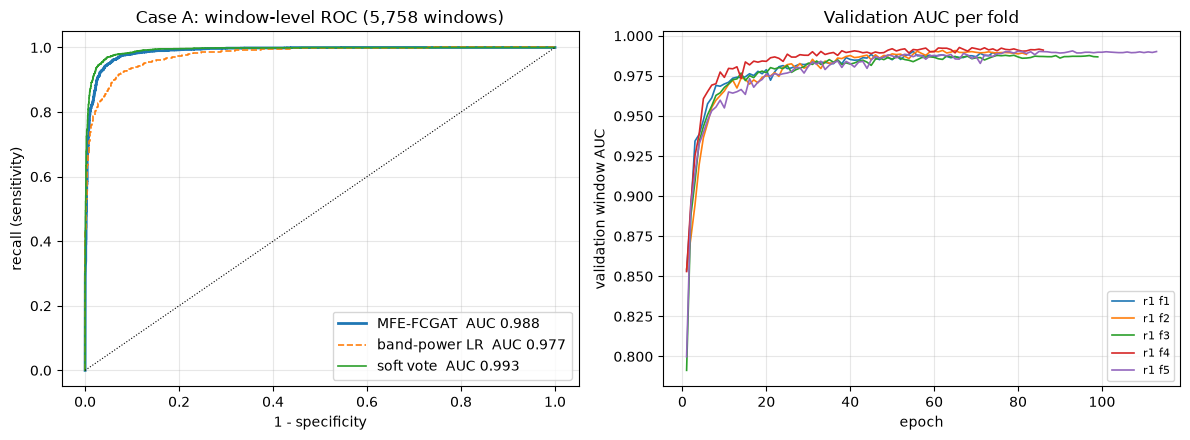

In [9]:
# ===========================================================================
# CELL 9 — RESULTS: Case A next to the paper's Table 3, and next to Case B
# ===========================================================================
COLS  = ["w_acc", "w_sens", "w_prec", "w_f1", "w_auc"]
PAPER = {   # Liu et al. 2025, Table 3: window-level split, mean of 20 runs
    "ResNet (paper)":                 (0.8580, 0.8561, 0.8512, 0.8530, 0.9306),
    "MI-GCN (paper)":                 (0.8485, 0.8637, 0.8327, 0.8463, 0.9006),
    "P-GCN (paper)":                  (0.8806, 0.8492, 0.8999, 0.8731, 0.9226),
    "GAT (paper's baseline)":         (0.9070, 0.9036, 0.8986, 0.9004, 0.9411),
    "MFE-FCGCN (paper's model)":      (0.9509, 0.9607, 0.9389, 0.9497, 0.9836),
}
print("=" * 96)
print(f"{'Case A: window level':44s}{'accuracy':>10s}{'recall':>10s}{'precision':>10s}{'F1':>10s}{'AUC':>10s}")
print("-" * 96)
for name, v in PAPER.items():
    print(f"{name:44s}" + "".join(f"{x:10.4f}" for x in v))
print("-" * 96)
print(f"{f'MFE-FCGAT, ours (lr {LR:g}), pooled':44s}" + "".join(f"{P[c]:10.4f}" for c in COLS))
print(f"{'MFE-FCGAT, ours, fold mean':44s}" + "".join(f"{F_MEAN[c]:10.4f}" for c in COLS))
print(f"{'   +- SD over folds':44s}" + "".join(f"{F_SD[c]:10.4f}" for c in COLS))
print(f"{'band-power logistic regression, same folds':44s}" + "".join(f"{FLOOR[c]:10.4f}" for c in COLS))
# soft vote: mean of the two models' P(AD), equal weights, nothing tuned (same as Case B's Cell 10)
ENS_OOF = (OOF + FLOOR_OOF) / 2
ENS = pd.DataFrame([score(np.arange(len(Y)), ENS_OOF[r]) for r in range(N_REPEATS)]).mean()
np.save(RESULT_DIR / "ensemble_oof_prob.npy", ENS_OOF)
print(f"{'soft vote: GAT + band power, pooled':44s}" + "".join(f"{ENS[c]:10.4f}" for c in COLS))
print("=" * 96)
gap = {k: P[c] - PAPER["MFE-FCGCN (paper's model)"][i] for i, (k, c) in
       enumerate(zip(["accuracy", "recall", "precision", "F1", "AUC"], COLS))}
print("ours - paper's MFE-FCGCN: " + "   ".join(f"{k} {v:+.4f}" for k, v in gap.items()))

# --- Case B, for contrast (written by GAT_ds004504.ipynb) ----------------------
case_b = WORK_DIR / "results_gat" / "summary.json"
if case_b.exists():
    b = json.loads(case_b.read_text())["pooled"]
    print(f"\nCase B, same model, SUBJECT split (new patients, GAT_ds004504.ipynb):\n"
          f"  subject level  acc {b['s_acc']:.4f}  recall {b['s_sens']:.4f}  specificity {b['s_spec']:.4f}  AUC {b['s_auc']:.4f}\n"
          f"  window level   acc {b['w_acc']:.4f}  recall {b['w_sens']:.4f}  specificity {b['w_spec']:.4f}  AUC {b['w_auc']:.4f}\n"
          f"  The gap between the two cases is the part of Case A that comes from seeing the same people in training.")

print(f"\nbest epochs: {FOLDS.best_epoch.tolist()}   (cap {MAX_EPOCHS})")
if (FOLDS.epochs_run == MAX_EPOCHS).mean() >= 0.6:
    print("  -> most folds were still improving at the cap: raise MAX_EPOCHS")

# --- plots --------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
_p, _fp = np.nanmean(OOF, axis=0), np.nanmean(FLOOR_OOF, axis=0)
ax[0].plot(*roc_curve(Y, _p)[:2], lw=2, label=f"MFE-FCGAT  AUC {roc_auc_score(Y, _p):.3f}")
ax[0].plot(*roc_curve(Y, _fp)[:2], lw=1.2, ls="--", label=f"band-power LR  AUC {roc_auc_score(Y, _fp):.3f}")
_ep = np.nanmean(ENS_OOF, axis=0)
ax[0].plot(*roc_curve(Y, _ep)[:2], lw=1.2, label=f"soft vote  AUC {roc_auc_score(Y, _ep):.3f}")
ax[0].plot([0, 1], [0, 1], "k:", lw=0.8)
ax[0].set(xlabel="1 - specificity", ylabel="recall (sensitivity)",
          title=f"Case A: window-level ROC ({len(Y):,} windows)")
ax[0].legend(); ax[0].grid(alpha=0.3)

for (r, f), h in HISTORY.items():
    ax[1].plot(h.epoch, h.val_w_auc, lw=1.2, label=f"r{r} f{f}")
ax[1].set(xlabel="epoch", ylabel="validation window AUC", title="Validation AUC per fold")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULT_DIR / "summary.png", dpi=140)
plt.show()

---
## Reading the result

- **Present Case A and Case B together, each with its label.** Case A answers
  "does it recognise AD in more recordings of people it has seen?"; Case B
  answers "does it work on a new patient?". The base paper reports only the
  Case A kind of number.
- **Compare Case A with the paper's Table 3 and with the floor in Cell 5.**
  Under a window split, a logistic regression on band power already scores
  about 0.92 without any graph, so most of a Case A score comes from the split
  itself. What the GAT adds is the gap above that floor.
- **Fold mean ± SD is the paper's format** (they averaged 20 runs of an 80 / 20
  split; each of our folds is one such run). The pooled row scores every window
  once and is the steadier number.
- Subject-level numbers are not reported here: in Case A every subject has
  windows in training, so a per-subject vote is close to 100 % by construction.